# CAPM, the Security Market Line and Betas in R: Rolling OLS, Kalman Filter, Bayesian Shrinkage and Machine Learning

Beta is everywhere in finance: in the cost of equity, in hedge ratios, in performance attribution. Yet it is never observed, and a five-year estimate is noisy and drifts. This notebook uses sixty years of U.S. returns to ask whether the CAPM actually holds, and which way of estimating beta best predicts the beta that follows.

**What it does.** It uses 60 years of U.S. portfolio returns to answer two questions about beta.

1. **Does the CAPM hold?** The security market line is tested on ten beta-sorted portfolios with time-series alphas, the GRS test and Fama–MacBeth cross-sectional regressions.
2. **How should beta be estimated?** Six forecasts of each of 49 industries' beta over the next three years are compared out of sample: rolling OLS, the Blume adjustment, Vasicek's Bayesian shrinkage, a **Kalman filter** with time-varying beta (written from scratch), a **random forest** and **XGBoost**.

**Data.** The Kenneth French Data Library (monthly market factor and risk-free rate, 49 value-weighted industry portfolios, and portfolios formed on market beta, all since 1963).

**Methods.** OLS and Newey–West, the GRS F-test, Fama–MacBeth (plain t-statistics, no Shanken correction), a random-walk-beta state-space model by maximum likelihood, empirical-Bayes shrinkage, and `ranger` and `xgboost` with a rolling panel design.

**Key output.** The empirical SML against the CAPM line, alphas by beta decile, and the forecast error of each beta method.

## 1. The CAPM and why beta estimation matters

The CAPM says an asset's expected excess return is proportional to its beta against the market: E[r_i − r_f] = β_i · E[r_m − r_f]. Plotted against beta, expected returns should lie on the **security market line** (SML), which passes through zero and the market.

Beta is used everywhere in finance:
- **cost of equity** in valuation and in regulated tariffs;
- **hedge ratios** against index futures;
- **performance attribution:** alpha is what beta does not explain.

But beta is not observed. A 60-month OLS estimate has a standard error of about 0.1–0.2 and drifts over time. Three classic fixes exist:
- **Blume (1971):** betas regress towards 1, so use 0.67·β̂ + 0.33;
- **Vasicek (1973):** a Bayesian posterior that shrinks each estimate towards the cross-sectional mean, more strongly when the estimate is noisy;
- **time-varying beta:** let beta follow a random walk and estimate it with a Kalman filter.

Machine learning adds a fourth option: learn from the panel which combination of past estimates and characteristics predicts the future beta best.

## 2. Setup

In [ ]:
# -(install once with `Rscript install_packages.R` from the repo root)- #
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
# nolint
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14,
        repr.plot.height = 5, repr.plot.res = 110)
# plain-text tables in the notebook (no ANSI colour codes) # nolint
options(crayon.enabled = FALSE, cli.num_colors = 1)

# --- Folders and credentials
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR,
                      "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR,
           showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
# look for .env in this folder and its parents (like python-dotenv)
find_env <- function(start = getwd()) {
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
# tolerate a missing final newline
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))

# --- Cache helper: every download is stored in data/ and reused for 12 hours
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) &&
      difftime(Sys.time(), file.mtime(path),
               units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) { message(name, ": download failed (",
                                     conditionMessage(e),
                                     "); using cached copy"); return(readRDS(path)) }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts)
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
             "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA),
          panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.major = element_line(colour = GRID),
            panel.grid.minor = element_blank(),
          plot.title = element_text(face = "bold", colour = INK, size = 12),
            plot.title.position = "plot",
          axis.text = element_text(colour = INK_2),
            axis.title = element_text(colour = INK_2),
          legend.position = "top", legend.title = element_blank())
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14,
                     height = 5) ggsave(file.path(
                         OUT_DIR, paste0(name, ".png")),
                                        p, width = width, height = height,
                                        dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN
# (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf('<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
                  title, SURFACE,
                    toJSON(list(data = b$data, layout = b$layout),
                           auto_unbox = TRUE, null = "null", na = "null",
                           force = TRUE, digits = NA))
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages({
  library(httr2)
  library(ranger)
  library(xgboost)
})
KF_URL <- "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
EST_WIN <- 60            # months in the rolling estimation window
# months over which the realised (target) beta is measured
FWD_WIN <- 36
OOS_START <- 1985        # first year of out-of-sample beta forecasts
set.seed(11)
cat(sprintf("R %s · ranger %s · xgboost %s · run on %s\n", getRversion(),
            packageVersion("ranger"), packageVersion("xgboost"), Sys.Date()))

R 4.3.3 · ranger 0.18.0 · xgboost 3.2.1.1 · run on 2026-10-20


## 3. Data from the Kenneth French library

Each zip holds a CSV with several blocks (value-weighted monthly, equal-weighted, annual...). The value-weighted monthly block is read, −99.99 is treated as missing, and percentages become decimals.
- **Factors:** Mkt-RF (the value-weighted US market minus the T-bill) and RF.
- **49 industries:** value-weighted, from July 1963 (some industries start later).
- **Beta deciles:** stocks are sorted each June on their past 60-month beta. These pre-formation-beta portfolios are the standard test assets for the SML.

In [2]:
read_kf <- function(file, block = "Value Weighted Returns -- Monthly") {
  raw <- cached(sub(".zip", "", file), function() {
    tmp <- tempfile(fileext = ".zip")
    request(paste0(KF_URL, file)) |>
      req_timeout(120) |>
      req_perform(path = tmp)
    readLines(unz(tmp, unzip(tmp, list = TRUE)$Name[1]), warn = FALSE)
  }, max_age_hours = 24 * 7)
  start <- if (is.null(block)) 1 else grep(block, raw, fixed = TRUE)[1]
  hdr <- start - 1 + grep("^\\s*,", raw[start:length(raw)])[1]
  end <- hdr + which(!grepl("^\\s*[0-9]{6}", raw[(hdr + 1):length(raw)]))[1] -
    1
  d <- read.csv(
    text = paste(raw[hdr:end], collapse = "\n"),
    check.names = FALSE, strip.white = TRUE
  )
  names(d) <- trimws(names(d)); names(d)[1] <- "ym"
  d |>
    mutate(
      date = as.Date(paste0(ym, "01"), "%Y%m%d"),
      across(-c(ym, date), \(v) ifelse(v <= -99.99, NA, v / 100))
    ) |>
    select(-ym) |>
    relocate(date)
}
ff <- read_kf("F-F_Research_Data_Factors_CSV.zip", block = NULL)
ind <- read_kf("49_Industry_Portfolios_CSV.zip")
bdec <- read_kf("Portfolios_Formed_on_BETA_CSV.zip") |>
  select(date, `Lo 10`, starts_with("Dec"), `Hi 10`)
names(bdec) <- c("date", paste0("β", 1:10))
ff <- ff |>
  transmute(date, mkt = `Mkt-RF`, rf = RF) |>
  filter(!is.na(mkt))
ex_ind <- ind |>
  inner_join(ff, by = "date") |>
  mutate(across(-c(date, mkt, rf), \(v) v - rf))
ex_bd <- bdec |>
  inner_join(ff, by = "date") |>
  mutate(across(-c(date, mkt, rf), \(v) v - rf))
INDS <- setdiff(names(ind), "date")
cat(sprintf(
  "Factors %s → %s · %d industries · beta deciles %s → %s\n",
  min(ff$date), max(ff$date), length(INDS), min(bdec$date),
  max(bdec$date)
))

Factors 1926-07-01 → 2026-08-01 · 49 industries · beta deciles 1963-07-01 → 2026-08-01


## 4. Does the CAPM hold? The SML on beta-sorted portfolios

For each beta decile:
- **time-series regression** r_i − r_f = α_i + β_i·(r_m − r_f) + ε with Newey–West errors (6 lags);
- the **GRS test** (Gibbons, Ross and Shanken, 1989) of all ten alphas being zero jointly;
- **Fama–MacBeth (1973):** each month, regress the ten portfolios' excess returns on their betas from the prior 60 months. The time series of slopes estimates the price of beta risk, to be compared with the average market excess return, which is what the CAPM predicts.

In [3]:
Y <- as.matrix(ex_bd[, paste0("β", 1:10)]); m <- ex_bd$mkt
# HAC covariance of OLS coefficients with Bartlett weights
newey_west <- function(fit, L) {
  X <- model.matrix(fit); u <- resid(fit); n <- nrow(X)
  S <- crossprod(X * u)
  for (l in 1:L) { G <- crossprod(X[(l + 1):n, , drop = FALSE] * u[(l + 1):n],
                                  X[1:(n - l), , drop = FALSE] *
                                  u[1:(n - l)]); S <- S +
                  (1 - l / (L + 1)) * (G + t(G)) }
  B <- solve(crossprod(X)); B %*% S %*% B
}
ts_reg <- map_dfr(1:10, function(i) {
  f <- lm(Y[, i] ~ m)
  tibble(portfolio = paste0("β", i), beta = coef(f)[2],
         `alpha (% p.a.)` = 1200 * coef(f)[1], `alpha t (NW)` = coef(f)[1] /
         sqrt(newey_west(f, 6)[1, 1]),
         `mean excess (% p.a.)` = 1200 * mean(Y[, i]),
           `CAPM prediction (% p.a.)` = 1200 * coef(f)[2] * mean(m),
           R2 = summary(f)$r.squared)
})
grs <- function(Y, m) {
  Tn <- nrow(Y); N <- ncol(Y)
  fits <- lm(Y ~ m); a <- coef(fits)[1, ]; E <- resid(fits)
  S <- crossprod(E) / (Tn - 2)
  stat <- (Tn / N) * ((Tn - N - 1) / (Tn - 2)) * drop(t(a) %*% solve(S, a)) /
    (1 + mean(m) ^ 2 / var(m))
  c(F = stat, p = 1 - pf(stat, N, Tn - N - 1))
}
G <- grs(Y, m)
# Fama–MacBeth with rolling pre-estimated betas
fm <- map_dfr((EST_WIN + 1):nrow(Y), function(t) {
  w <- (t - EST_WIN):(t - 1)
  b <- apply(Y[w, ], 2, function(y) coef(lm(y ~ m[w]))[2])
  g <- coef(lm(Y[t, ] ~ b))
  tibble(date = ex_bd$date[t], g0 = g[1], g1 = g[2], mkt = m[t])
})
fm_tab <- tibble(statistic = c("intercept γ0 (% p.a.)",
                               "price of beta γ1 (% p.a.)",
                               "CAPM: market premium (% p.a.)"),
                 estimate = 1200 * c(mean(fm$g0), mean(fm$g1), mean(fm$mkt)),
                 `t-stat` = c(mean(fm$g0) / sd(fm$g0) * sqrt(nrow(fm)),
                              mean(fm$g1) / sd(fm$g1) * sqrt(nrow(fm)),
                              mean(fm$mkt) / sd(fm$mkt) * sqrt(nrow(fm))))
cat(sprintf("GRS test of ten zero alphas: F = %.2f, p = %.4f · %d months\n",
            G["F"], G["p"], nrow(Y)))
print(fm_tab |> mutate(across(where(is.numeric), \(v) round(v, 2))))
ts_reg |> mutate(across(where(is.numeric), \(v) round(v, 3)))

GRS test of ten zero alphas: F = 2.04, p = 0.0272 · 758 months


# A tibble: 3 × 3
  statistic                     estimate `t-stat`
  <chr>                            <dbl>    <dbl>
1 intercept γ0 (% p.a.)             4.71     1.9 
2 price of beta γ1 (% p.a.)         2.9      0.88
3 CAPM: market premium (% p.a.)     7.13     3.44


portfolio,beta,alpha (% p.a.),alpha t (NW),mean excess (% p.a.),CAPM prediction (% p.a.),R2
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
β1,0.594,2.509,2.554,6.799,4.290,0.584
β2,0.717,1.135,1.277,6.310,5.175,0.714
β3,0.843,1.266,1.680,7.350,6.084,0.833
β4,0.976,1.311,1.500,8.361,7.050,0.871
β5,1.015,0.303,0.503,7.631,7.328,0.893
β6,1.100,0.255,0.330,8.197,7.942,0.881
β7,1.170,-0.465,-0.581,7.988,8.453,0.891
β8,1.282,0.610,0.563,9.865,9.254,0.862
β9,1.402,0.434,0.298,10.559,10.125,0.824


**Is it stable over time?** The same SML slope (high-beta minus low-beta decile return, scaled by their beta difference) is computed by decade.

In [4]:
by_dec <- ex_bd |>
  mutate(decade = paste0(
    10 * floor(as.integer(format(date, "%Y")) / 10),
    "s"
  )) |>
  group_by(decade) |>
  group_modify(function(d, ...) {
    b1 <- coef(lm(d$β1 ~ d$mkt))[2]; b10 <- coef(lm(d$β10 ~ d$mkt))[2]
    tibble(
      months = nrow(d), `beta, low` = b1, `beta, high` = b10,
      `market premium (% p.a.)` = 1200 * mean(d$mkt),
      `SML slope implied by deciles (% p.a.)` = 1200 *
        (mean(d$β10) - mean(d$β1)) / (b10 - b1),
      `alpha high − low (% p.a.)` = 1200 *
        ((mean(d$β10) - b10 * mean(d$mkt)) - (mean(d$β1) - b1 * mean(d$mkt)))
    )
  }) |>
  ungroup()
by_dec |> mutate(across(where(is.numeric), \(v) round(v, 2)))

decade,months,"beta, low","beta, high",market premium (% p.a.),SML slope implied by deciles (% p.a.),alpha high − low (% p.a.)
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1960s,78,0.74,1.68,4.50,13.49,8.40
1970s,120,0.75,1.65,1.18,-1.80,-2.66
1980s,120,0.58,1.45,8.56,-9.80,-15.92
1990s,120,0.62,1.50,12.79,12.88,0.08
2000s,120,0.50,1.76,-1.70,-3.30,-2.02
2010s,120,0.55,1.69,13.14,0.91,-14.02
2020s,80,0.47,1.58,13.08,7.49,-6.24


## 5. A Kalman filter for time-varying beta

The state-space model for each industry:

r_t − r_f = α + β_t·(r_m,t − r_f) + ε_t,  ε_t ~ N(0, σ²_ε)
β_t = β_{t−1} + η_t,  η_t ~ N(0, σ²_η)

The Kalman filter gives the best linear estimate of β_t from data up to t. The measurement variance σ²_ε comes from each industry's OLS residuals before 1985. The beta-noise variance σ²_η is estimated by maximum likelihood (prediction-error decomposition) **pooled across all 49 industries** on the same pre-1985 data, then held fixed.

Estimated one industry at a time, σ²_η is poorly identified and sometimes explodes, producing betas that swing wildly. A small σ_η means beta is nearly constant; a large one means it moves and old data should be discounted. α is held at zero for simplicity: monthly alphas are tiny next to beta's contribution.

In [5]:
kalman_beta <- function(y, x, s2e, s2n, b0 = 1, P0 = 1) {
  n <- length(y); b <- numeric(n); P <- numeric(n); ll <- 0
  bp <- b0; Pp <- P0
  for (t in seq_len(n)) {
    Pp <- Pp + s2n # predict
    if (!is.na(y[t])) {
      F_ <- x[t]^2 * Pp + s2e; v <- y[t] - x[t] * bp
      ll <- ll - 0.5 * (log(2 * pi * F_) + v^2 / F_)
      K <- Pp * x[t] / F_; bp <- bp + K * v; Pp <- (1 - K * x[t]) * Pp
    }
    b[t] <- bp; P[t] <- Pp
  }
  list(beta = b, P = P, ll = ll)
}
est_start <- which(ex_ind$date >= as.Date(paste0(OOS_START, "-01-01")))[1]
# measurement noise per industry from an OLS fit on the pre-1985 data; one
# beta-noise variance shared by all industries,
# chosen by maximising the summed likelihood (per-industry estimates of σ²_η
# are badly identified and sometimes explode)
pre <- 1:(est_start - 1)
S2E <- sapply(INDS, function(i) {
  y <- ex_ind[[i]][pre]; ok <- !is.na(y); if (sum(ok) < 60) return(NA); var(resid(lm(y[ok] ~ ex_ind$mkt[pre][ok])))
})
S2E[is.na(S2E)] <- median(S2E, na.rm = TRUE)
pooled_ll <- function(ls2n) sum(sapply(
  INDS,
  function(i) kalman_beta(
    ex_ind[[i]][pre], ex_ind$mkt[pre],
    S2E[[i]], exp(ls2n)
  )$ll
))
opt <- optimize(function(v) -pooled_ll(v), c(log(1e-7), log(0.01)))
S2N <- exp(opt$minimum)
KF_PAR <- tibble(industry = INDS, s2e = S2E, s2n = S2N)
BK <- sapply(
  INDS,
  function(i) kalman_beta(
    ex_ind[[i]], ex_ind$mkt, S2E[[i]],
    S2N
  )$beta
)
lr_ <- 2 * (-opt$objective - pooled_ll(log(1e-7)))
cat(sprintf(
  "Pooled beta noise: sd of the monthly beta change %.4f (≈ %.2f per year) · likelihood-ratio statistic vs constant beta %.1f\n",
  sqrt(S2N), sqrt(12 * S2N), lr_
))

Pooled beta noise: sd of the monthly beta change 0.0535 (≈ 0.19 per year) · likelihood-ratio statistic vs constant beta 1534.9


## 6. Forecasting beta: six methods out of sample

**Design.** At every December from 1984, for every industry with enough history:
- **target:** the OLS beta over the **next 36 months**, the beta a valuation or hedge set today will face;
- **forecasts**, using data up to that December only:
  1. **OLS 60m:** the rolling 60-month beta;
  2. **Blume:** 0.67·OLS + 0.33;
  3. **Vasicek:** posterior mean (β̂/s² + β̄/τ²)/(1/s² + 1/τ²), where s is each estimate's standard error, β̄ the cross-sectional mean and τ² the cross-sectional variance net of sampling noise;
  4. **Kalman:** the filtered beta at that date;
  5. **random forest** and 6. **XGBoost:** trained on all industry-years whose target window has fully ended by that December (so no future information leaks in). The features are the four estimates above, 24- and 120-month OLS betas, the industry's 60-month volatility, idiosyncratic volatility and correlation with the market, the market's volatility, and the industry's 12-month return.

The score is the mean squared error against the realised 36-month beta. A naive forecast of 1.0 for everyone is included as a reference.

In [6]:
ols_beta <- function(y, x) {
  ok <- !is.na(y); if (sum(ok) < 24) return(c(
      NA, NA, NA)); f <- lm(y[ok] ~ x[ok]); s <- summary(f)
  c(coef(f)[2], s$coefficients[2, 2], s$sigma)
}
dec_idx <- which(format(ex_ind$date, "%m") == "12" &
                 seq_len(nrow(ex_ind)) >= 120)
rows <- list()
for (t in dec_idx) {
  w60 <- (t - 59):t; w24 <- (t - 23):t; w120 <- (t - 119):t
  xm <- ex_ind$mkt
  for (i in INDS) {
    y <- ex_ind[[i]]
    if (sum(!is.na(y[w60])) < 60) next
    o60 <- ols_beta(y[w60], xm[w60]); o24 <- ols_beta(y[w24],
                    xm[w24]); o120 <- ols_beta(y[w120], xm[w120])
    fwd <- if (t + FWD_WIN <= nrow(ex_ind)) ols_beta(y[(t + 1):(t + FWD_WIN)],
               xm[(t + 1):(t + FWD_WIN)])[1] else NA
    rows[[length(rows) + 1]] <- tibble(
      date = ex_ind$date[t], year = as.integer(format(ex_ind$date[t], "%Y")),
        industry = i, ols60 = o60[1], se60 = o60[2],
      ols24 = o24[1], ols120 = o120[1], kalman = BK[t, i], vol60 = sd(y[w60]),
        idio60 = o60[3], corr60 = cor(y[w60], xm[w60]),
      mktvol60 = sd(xm[w60]), ret12 = sum(y[(t - 11):t]), target = fwd
    )
  }
}
P <- bind_rows(rows) |>
  group_by(date) |>
  mutate(
    bbar = mean(ols60), tau2 = pmax(var(ols60) - mean(se60^2), 0.01),
    vasicek = (ols60 / se60^2 + bbar / tau2) / (1 / se60^2 + 1 / tau2),
      blume = 0.67 * ols60 + 0.33
  ) |>
  ungroup()
FEAT <- c("ols60", "ols24", "ols120", "blume", "vasicek", "kalman", "se60",
          "vol60", "idio60", "corr60", "mktvol60", "ret12")
P$rf <- NA_real_; P$xgb <- NA_real_
for (yr in OOS_START:max(P$year)) {
  te <- which(P$year == yr)
  # target window ended by this December
  tr <- which(P$year <= yr - FWD_WIN / 12 & !is.na(P$target) &
              complete.cases(P[, FEAT]))
  te <- te[complete.cases(P[te, FEAT])]
  if (length(tr) < 300 || length(te) == 0) next
  rfm <- ranger(x = P[tr, FEAT], y = P$target[tr], num.trees = 400,
                min.node.size = 20, mtry = 4, seed = 11)
  P$rf[te] <- predict(rfm, P[te, FEAT])$predictions
  bst <- xgb.train(
    params = list(objective = "reg:squarederror", eta = 0.03, max_depth = 3,
                  min_child_weight = 20, subsample = 0.8, nthread = 2),
    data = xgb.DMatrix(as.matrix(P[tr, FEAT]), label = P$target[tr]),
      nrounds = 400, verbose = 0
  )
  P$xgb[te] <- predict(bst, as.matrix(P[te, FEAT]))
}
E <- P |>
  filter(year >= OOS_START, !is.na(target), !is.na(rf), !is.na(xgb)) |>
  mutate(naive = 1)
METHODS <- c(`naive (β = 1)` = "naive", `OLS 60m` = "ols60", Blume = "blume",
             Vasicek = "vasicek", Kalman = "kalman", `random forest` = "rf",
             XGBoost = "xgb")
SCORE <- imap_dfr(METHODS, function(col, nm) {
  e <- E[[col]] - E$target
  tibble(method = nm, MSE = mean(e^2), `mean error` = mean(e),
         MAE = mean(abs(e)))
}) |> mutate(`MSE vs OLS 60m` = MSE / MSE[method == "OLS 60m"])
# Diebold–Mariano-style test of each method against OLS, clustering by forecast
# date
dm <- function(col) {
  d <- E |>
    mutate(dl = (E$ols60 - E$target)^2 - (E[[col]] - E$target)^2) |>
    group_by(date) |>
    summarise(dl = mean(dl))
  mean(d$dl) / (sd(d$dl) / sqrt(nrow(d)))
}
SCORE$`t-stat gain vs OLS` <- sapply(METHODS,
                                     function(cl) if (cl == "ols60") NA else dm(cl))
cat(sprintf("%s industry-year forecasts, %d–%d\n",
            format(nrow(E), big.mark = ","), min(E$year), max(E$year)))
SCORE |> mutate(across(where(is.numeric), \(v) round(v, 4)))

1,862 industry-year forecasts, 1985–2022


method,MSE,mean error,MAE,MSE vs OLS 60m,t-stat gain vs OLS
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
naive (β = 1),0.1549,-0.0218,0.2993,1.2892,-3.0849
OLS 60m,0.1201,-0.0004,0.2512,1.0000,NA
Blume,0.1031,-0.0075,0.2320,0.8579,3.2321
Vasicek,0.1124,-0.0024,0.2424,0.9358,3.0683
Kalman,0.1094,-0.0026,0.2429,0.9108,1.5727
random forest,0.1050,0.0089,0.2340,0.8743,1.9204
XGBoost,0.1018,-0.0006,0.2303,0.8477,2.2962


In [7]:
imp_rf <- ranger(
  x = E[, FEAT], y = E$target, num.trees = 400,
  min.node.size = 20, mtry = 4, importance = "permutation",
  seed = 11
)$variable.importance
IMP <- tibble(feature = names(imp_rf), importance = imp_rf / sum(imp_rf)) |>
  arrange(desc(importance))
# final ML forecast for today: train on every completed target window
trf <- which(!is.na(P$target) & complete.cases(P[, FEAT]))
rf_last <- ranger(
  x = P[trf, FEAT], y = P$target[trf], num.trees = 400,
  min.node.size = 20, mtry = 4, seed = 11
)
cur <- P |> filter(date == max(date))
LATEST <- cur |>
  transmute(industry,
    `OLS 60m` = ols60, Blume = blume, Vasicek = vasicek, Kalman = kalman,
    `random forest` = predict(rf_last, cur[, FEAT])$predictions
  ) |>
  arrange(desc(`random forest`))
print(IMP |> mutate(importance = round(importance, 3)))
cat(sprintf(
  "Betas as of %s (highest and lowest by the random forest):\n",
  max(P$date)
))
bind_rows(head(LATEST, 6), tail(LATEST, 6)) |>
  mutate(across(where(is.numeric), \(v) round(v, 2)))

# A tibble: 12 × 2
   feature  importance
   <chr>         <dbl>
 1 kalman        0.204
 2 vasicek       0.199
 3 blume         0.138
 4 ols60         0.121
 5 ols24         0.08 
 6 ols120        0.067
 7 corr60        0.047
 8 vol60         0.043
 9 idio60        0.041
10 mktvol60      0.026
11 se60          0.025
12 ret12         0.009


Betas as of 2025-12-01 (highest and lowest by the random forest):


industry,OLS 60m,Blume,Vasicek,Kalman,random forest
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Autos,1.79,1.53,1.39,2.03,1.51
FabPr,1.55,1.37,1.29,2.00,1.45
ElcEq,1.55,1.37,1.46,1.91,1.43
Steel,1.66,1.44,1.45,1.49,1.36
Cnstr,1.42,1.28,1.35,1.51,1.28
Txtls,1.25,1.17,1.16,1.15,1.27
Hshld,0.52,0.68,0.57,0.34,0.60
Soda,0.36,0.57,0.43,0.18,0.58
Smoke,0.38,0.59,0.50,0.15,0.58


## 7. Charts and dashboard

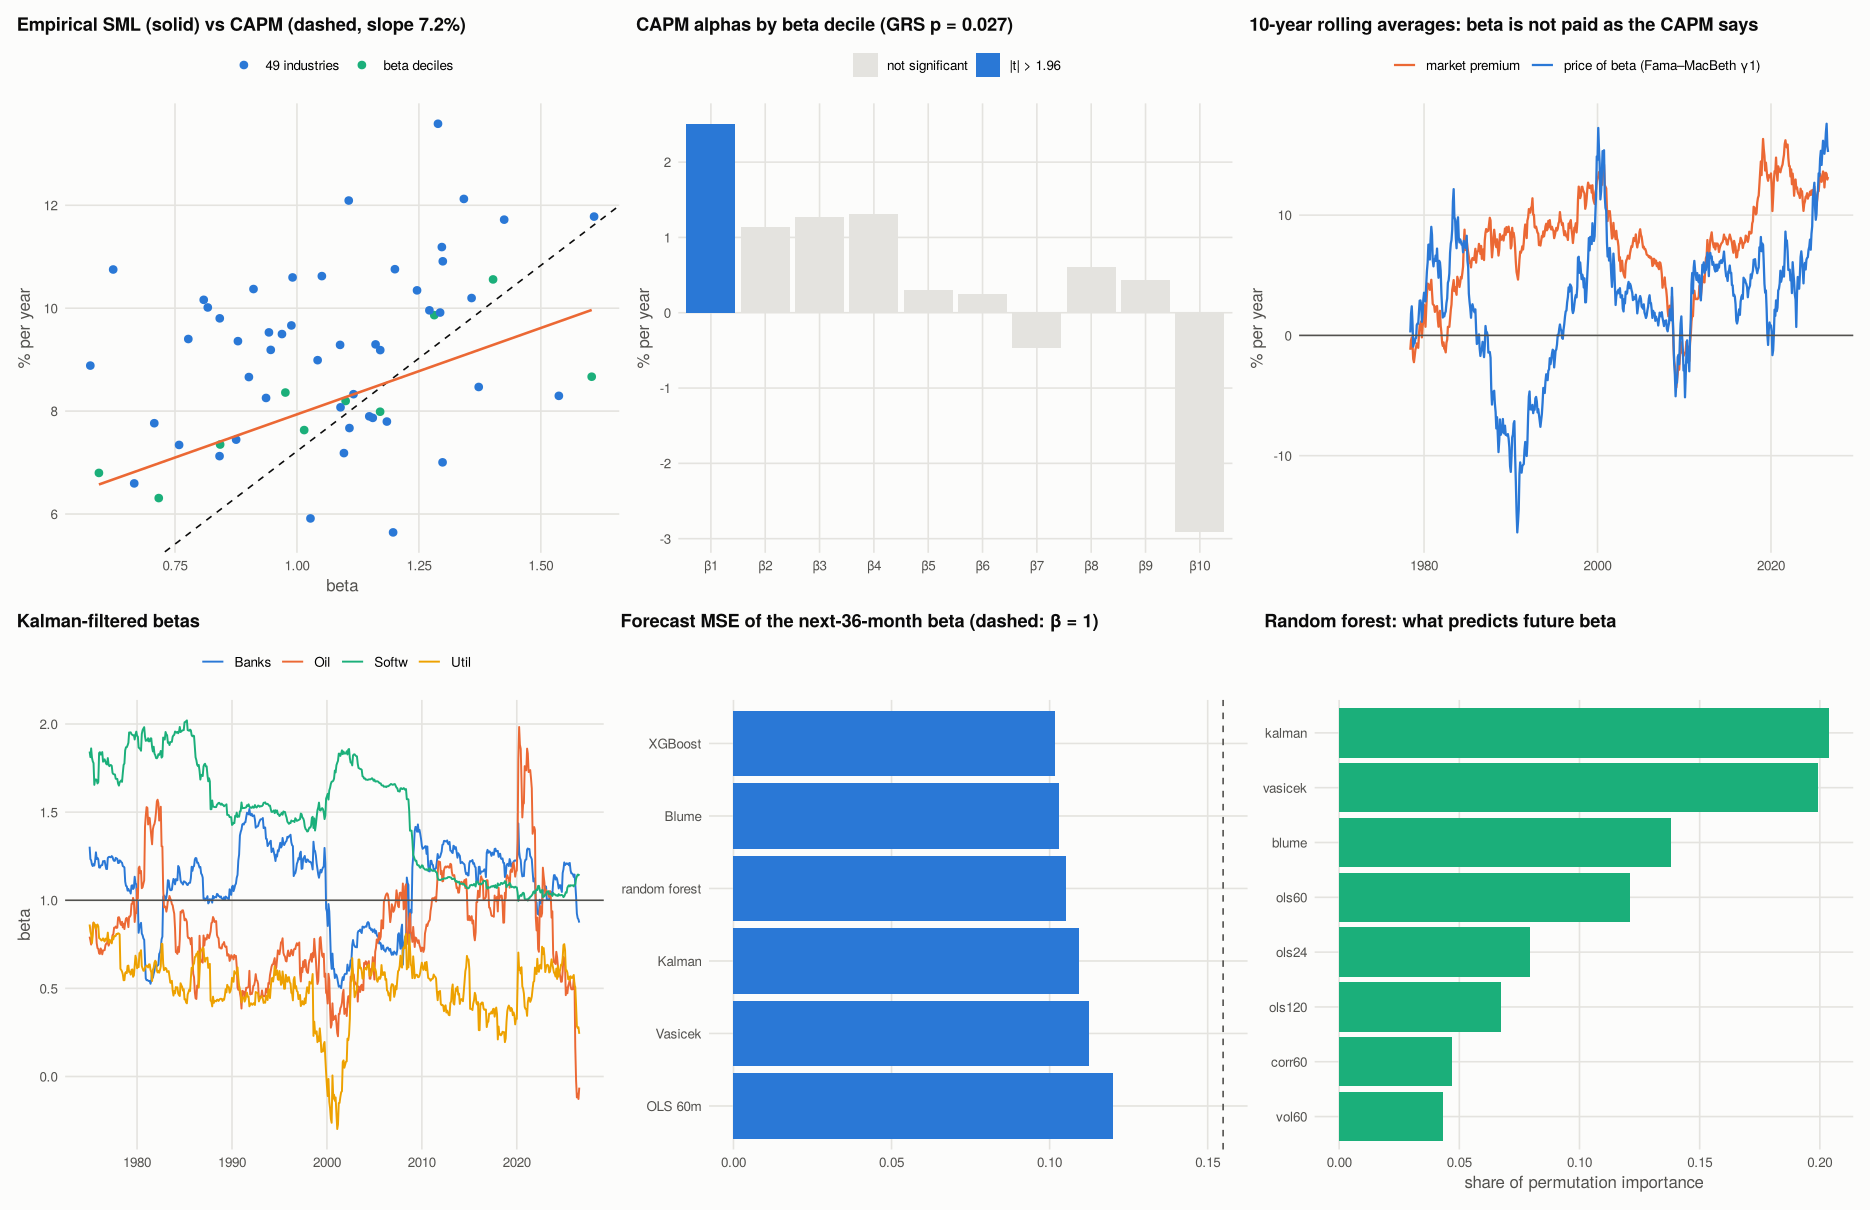

In [ ]:
options(repr.plot.width = 17, repr.plot.height = 11)
sml <- ts_reg |> mutate(type = "beta deciles")
ind_full <- map_dfr(INDS, function(i) {
  ok <- !is.na(ex_ind[[i]]); f <- lm(ex_ind[[i]][ok] ~ ex_ind$mkt[ok])
  tibble(portfolio = i, beta = coef(f)[2], `mean excess (% p.a.)` = 1200 *
    mean(ex_ind[[i]][ok]), type = "49 industries")
})
mp <- 1200 * mean(m)
p1 <- ggplot(
  bind_rows(sml, ind_full),
  aes(beta, `mean excess (% p.a.)`, colour = type)
) +
  geom_point(size = 2) +
  geom_abline(intercept = 0, slope = mp, colour = INK, linetype = "dashed") +
  geom_smooth(
    data = sml, method = "lm", se = FALSE, colour = PALETTE[2],
    linewidth = 0.8, formula = y ~ x
  ) +
  scale_colour_manual(values = PALETTE[c(1, 3)]) +
  labs(
    title = sprintf("Empirical SML (solid) vs CAPM (dashed, slope %.1f%%)",
                    mp),
    x = "beta", y = "% per year"
  )
p2 <- ts_reg |>
  mutate(portfolio = factor(portfolio, levels = portfolio)) |>
  ggplot(aes(portfolio, `alpha (% p.a.)`, fill = abs(`alpha t (NW)`) > 1.96)) +
  geom_col() +
  scale_fill_manual(
    values = c(`FALSE` = GRID, `TRUE` = PALETTE[1]),
    labels = c("not significant", "|t| > 1.96")
  ) +
  labs(
    title = sprintf("CAPM alphas by beta decile (GRS p = %.3f)", G["p"]),
    x = NULL, y = "% per year"
  )
p3 <- fm |>
  mutate(
    roll = zoo::rollmean(g1, 120, fill = NA, align = "right") * 1200,
    mk = zoo::rollmean(mkt, 120, fill = NA, align = "right") * 1200
  ) |>
  pivot_longer(c(roll, mk)) |>
  mutate(name = recode(name,
    roll = "price of beta (Fama–MacBeth γ1)",
    mk = "market premium"
  )) |>
  ggplot(aes(date, value, colour = name)) +
  geom_line(linewidth = 0.7, na.rm = TRUE) +
  geom_hline(yintercept = 0, colour = INK_2) +
  scale_colour_manual(values = PALETTE[c(2, 1)]) +
  labs(
    title = "10-year rolling averages: beta is not paid as the CAPM says",
    x = NULL, y = "% per year"
  )
ex_show <- c("Banks", "Softw", "Util", "Oil")
ex_show <- intersect(ex_show, INDS)
p4 <- tibble(date = ex_ind$date, as_tibble(BK[, ex_show])) |>
  filter(date >= as.Date("1975-01-01")) |>
  pivot_longer(-date) |>
  ggplot(aes(date, value, colour = name)) +
  geom_line(linewidth = 0.6) +
  geom_hline(yintercept = 1, colour = INK_2) +
  scale_colour_manual(values = PALETTE) +
  labs(title = "Kalman-filtered betas", x = NULL, y = "beta")
p5 <- SCORE |>
  filter(method != "naive (β = 1)") |>
  mutate(method = fct_reorder(method, -MSE)) |>
  ggplot(aes(method, MSE)) +
  geom_col(fill = PALETTE[1]) +
  coord_flip() +
  geom_hline(
    yintercept = SCORE$MSE[SCORE$method == "naive (β = 1)"],
    linetype = "dashed",
    colour = INK_2
  ) +
  labs(
    title = "Forecast MSE of the next-36-month beta (dashed: β = 1)",
    x = NULL, y = NULL
  )
p6 <- IMP |>
  head(8) |>
  mutate(feature = fct_reorder(feature, importance)) |>
  ggplot(aes(feature, importance)) +
  geom_col(fill = PALETTE[3]) +
  coord_flip() +
  labs(
    title = "Random forest: what predicts future beta", x = NULL,
    y = "share of permutation importance"
  )
p <- (p1 | p2 | p3) / (p4 | p5 | p6)
save_fig(p, "01_capm_sml_betas", width = 18, height = 11)
print(p)

In [9]:
d1 <- plot_ly(bind_rows(sml, ind_full),
  x = ~beta, y = ~`mean excess (% p.a.)`, color = ~type,
  colors = PALETTE[c(1, 3)], text = ~portfolio,
  type = "scatter", mode = "markers"
) |>
  add_lines(
    x = c(0.4, 1.8), y = mp * c(0.4, 1.8), name = "CAPM line",
    line = list(color = INK, dash = "dash"), inherit = FALSE
  )
d2 <- plot_ly(ts_reg,
  x = ~portfolio, y = ~`alpha (% p.a.)`, type = "bar",
  name = "alpha", marker = list(color = PALETTE[1])
)
d3 <- plot_ly(SCORE,
  x = ~method, y = ~MSE, type = "bar", name = "MSE",
  marker = list(color = PALETTE[2])
)
d4 <- plot_ly(
  tibble(date = ex_ind$date, as_tibble(BK[, ex_show])) |>
    filter(date >= as.Date("1975-01-01")) |> pivot_longer(-date),
  x = ~date, y = ~value, color = ~name, colors = PALETTE[1:4],
  type = "scatter", mode = "lines"
)
dash <- subplot(d1, d2, d3, d4, nrows = 2, margin = 0.07) |>
  layout(
    title = "CAPM, SML and beta forecasts", paper_bgcolor = SURFACE,
    plot_bgcolor = SURFACE
  )
save_plotly_html(dash, "dashboard", "CAPM and betas")
save_fig((p1 | p2) / (p4 | p5), "dashboard", width = 15, height = 10)

Dashboard saved: outputs/dashboard.html



## 8. Reading the results and limitations

**What the data say**

**The SML is too flat, as it has been since Black, Jensen and Scholes (1972).** Across the ten beta deciles (758 months, July 1963 to August 2026), full-sample betas run from 0.59 to 1.60. Average excess returns barely rise: 6.8% a year for the lowest-beta decile, 8.7% for the highest, and the peak is in decile 9 (10.6%). The CAPM predicts 4.3% and 11.6%.

- The low-beta decile has a significant alpha of +2.5% a year (Newey–West t = 2.6); the high-beta decile has −2.9% (t = −1.6).
- The **GRS test** rejects that all ten alphas are zero (F = 2.04, p = 0.027).

- **Fama–MacBeth confirms it.** The price of beta risk is 2.9% a year (t = 0.9) against a market premium of 7.1% (t = 3.4), and the intercept is 4.7% (t = 1.9) where the CAPM says zero. Beta is priced at less than half of what the model implies.
  - This is the **low-beta anomaly** behind "betting against beta" strategies (Frazzini and Pedersen, 2014).
  - Explanations include leverage constraints (investors who cannot borrow buy high-beta stocks instead) and lottery preferences.
- **It is not stable.** The slope implied by the deciles was steep in the 1960s and 1990s (13% a year), negative in the 1970s, 1980s and 2000s, and flat in the 2010s, when the high-beta decile underperformed the low-beta decile by 14% a year on a risk-adjusted basis despite a 13% market premium.
- **Betas do move.** The pooled Kalman model estimates that a beta drifts by about 0.05 a month (0.19 a year in standard deviation). The likelihood-ratio statistic against constant betas is 1,535, overwhelming.
- **Forecasting beta: shrinkage and ML beat raw OLS, and simple Blume is hard to beat.** Over 1,862 industry-year forecasts (1985–2022) of the next 36-month beta:
  - **XGBoost:** mean squared error 15% below the 60-month OLS beta;
  - **Blume:** −14%, with the strongest statistical evidence (t = 3.2);
  - **random forest:** −13%;
  - **Kalman:** −9%;
  - **Vasicek:** −6%;
  - **naive β = 1:** 29% worse.

  The ML models gain only about one percentage point over the one-line Blume rule, which is not statistically meaningful.
- **What the forest learns.** The most useful inputs are the Kalman and Vasicek estimates, then Blume and OLS; volatility, correlation and past returns add little. In effect, ML learns a better-calibrated combination of shrinkage estimators, which is why it ends up close to Blume.
- **Today's betas.** By the random forest, autos, fabricated products and electrical equipment are the highest-beta industries (1.4–1.5), and food, beer, gold and tobacco the lowest (0.4–0.6). The Kalman filter gives more extreme values (2.0 for autos, slightly negative for food) because it reacts to the last few years; that is its weakness as a forecast.

**Limitations**

- Industry and beta-sorted portfolios, not individual stocks. Stock-level betas are noisier, which favours shrinkage and ML even more.
- Monthly returns. Daily data give more precise betas, but they need corrections for non-synchronous trading (Scholes–Williams, Dimson).
- The target, a 36-month realised OLS beta, is itself noisy, which caps every method's achievable accuracy.
- The Fama–MacBeth t-statistics do not include the Shanken correction for estimated betas, so they overstate precision slightly. The conclusion, a flat SML, does not depend on it.
- The CAPM test uses a broad US equity index as the market. Roll's critique stands: the true market portfolio is unobservable.

In [10]:
write_csv(ts_reg, file.path(OUT_DIR, "beta_decile_alphas.csv"))
write_csv(fm_tab, file.path(OUT_DIR, "fama_macbeth.csv"))
write_csv(by_dec, file.path(OUT_DIR, "sml_by_decade.csv"))
write_csv(KF_PAR, file.path(OUT_DIR, "kalman_parameters.csv"))
write_csv(SCORE, file.path(OUT_DIR, "beta_forecast_scores.csv"))
write_csv(IMP, file.path(OUT_DIR, "rf_feature_importance.csv"))
write_csv(LATEST, file.path(OUT_DIR, "industry_betas_latest.csv"))
cat(
  "Outputs written:", paste(sort(list.files(OUT_DIR)), collapse = ", "),
  "\n"
)

Outputs written: 01_capm_sml_betas.png, beta_decile_alphas.csv, beta_forecast_scores.csv, dashboard.html, dashboard.png, fama_macbeth.csv, industry_betas_latest.csv, kalman_parameters.csv, rf_feature_importance.csv, sml_by_decade.csv 


## References

### Finance and regulation

- Sharpe, W. F. (1964). Capital asset prices: A theory of market equilibrium under conditions of risk. *The Journal of Finance, 19*(3), 425–442. https://doi.org/10.1111/j.1540-6261.1964.tb02865.x
- Fama, E. F., & MacBeth, J. D. (1973). Risk, return, and equilibrium: Empirical tests. *Journal of Political Economy, 81*(3), 607–636. https://doi.org/10.1086/260061
- Gibbons, M. R., Ross, S. A., & Shanken, J. (1989). A test of the efficiency of a given portfolio. *Econometrica, 57*(5), 1121–1152. https://doi.org/10.2307/1913625
- Blume, M. E. (1971). On the assessment of risk. *The Journal of Finance, 26*(1), 1–10. https://doi.org/10.1111/j.1540-6261.1971.tb00584.x
- Vasicek, O. A. (1973). A note on using cross-sectional information in Bayesian estimation of security betas. *The Journal of Finance, 28*(5), 1233–1239. https://doi.org/10.1111/j.1540-6261.1973.tb01452.x
- Frazzini, A., & Pedersen, L. H. (2014). Betting against beta. *Journal of Financial Economics, 111*(1), 1–25. https://doi.org/10.1016/j.jfineco.2013.10.005

### Machine learning and deep learning

- Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering, 82*(1), 35–45. https://doi.org/10.1115/1.3662552
- Wright, M. N., & Ziegler, A. (2017). ranger: A fast implementation of random forests for high dimensional data in C++ and R. *Journal of Statistical Software, 77*(1), 1–17. https://doi.org/10.18637/jss.v077.i01
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*. https://doi.org/10.1145/2939672.2939785